### Nugget Regularization Tests

Following the method outlined in Booker 1998, adding a regularization term to the correlation matrix to test effect on stability

In [81]:
%reload_ext autoreload
%autoreload 2

import os
import sys
module_path = os.path.abspath(os.path.join('SurrogateModels')) # or the path to your source code
sys.path.append(module_path)
!
print(module_path)


c:\Users\troyz\GitProjects\SurrogateModeling2\SurrogateModels


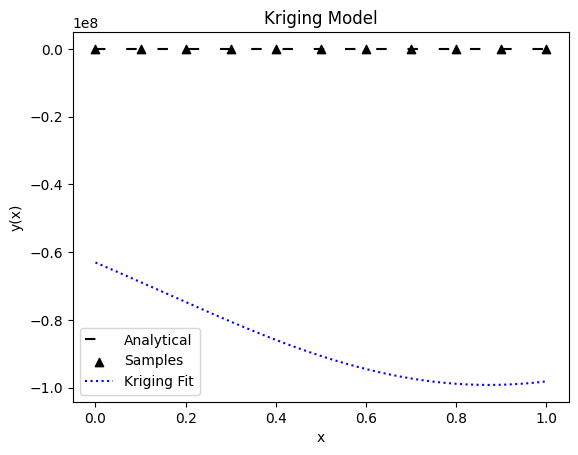

In [82]:
import numpy as np
import matplotlib.pyplot as plt
from SurrogateModels import mfs_functions, kriging

# Start with a synthetic dataset
#rng = np.random.RandomState(0)
fxn_ind = 1
dim,xmin,xmax=mfs_functions.function_bounds(fxn_ind)

n = 11

x = np.zeros((n,dim), dtype=float)

# Generate the analytical functions
lf_fxn = mfs_functions.cheap_fxn(1)

x[:,0] = np.linspace(xmin,xmax,n)
#Randomly changing x[3] from 0.3 to 0.35 fixes problem????
#x[3,0] = 0.35
np.random.shuffle(x[:,0])
y = lf_fxn.evaluate(x)
model = kriging.Kriging(x,y,1)

filename = "OutMatrices" + str(n)
model.print_model_params(filename)

x_vals = np.ones((300,1))
x_vals[:,0] = np.linspace(0,1,300)

plot_name = "Kriging Model"
lf_fxn.plot_model(x_vals,plot_name, color = "black",
                  linestyle = (0, (5, 10)), label = "Analytical")
model.plot_data(plot_name, color ="black", 
                label = "Samples", marker = '^')
model.plot_model(x_vals, name=plot_name, color="blue",
                    label = "Kriging Fit", linestyle='dotted')
plt.show()